# Figure 4 — Dinoflagellata differential expression (infected vs uninfected)

Standalone script for manuscript code availability. Produces:

1. Volcano plot (broken x-axis)
2. CSV of differentially expressed genes merged with eggNOG annotations

No external project modules are required beyond standard Python packages.

In [1]:
import os
from pathlib import Path
from typing import Iterable, List, Optional, Sequence, Set, Tuple, Union

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from matplotlib import gridspec
from matplotlib.lines import Line2D


In [2]:


def read_emapper_annotations(path: Union[str, Path]) -> pd.DataFrame:
    """Load eggNOG-mapper annotation file (.emapper.annotations)."""
    header = None
    skiprows: List[int] = []
    with Path(path).open() as handle:
        for idx, line in enumerate(handle):
            if line.startswith("##"):
                skiprows.append(idx)
            elif line.startswith("#query"):
                header = line.lstrip("#").strip().split("\t")
                skiprows.append(idx)
                break
    if header is None:
        raise ValueError(f"No #query header line found in {path}")
    return pd.read_csv(
        path,
        sep="\t",
        names=header,
        skiprows=skiprows,
        dtype=str,
        low_memory=False,
    )


def _read_gene_list(path: Union[str, Path]) -> List[str]:
    with Path(path).open() as handle:
        return [line.strip() for line in handle if line.strip()]


def get_viral_genes(
    path_viral_list: Union[str, Path],
    eggnog: pd.DataFrame,
    path_ail3_list: Optional[Union[str, Path]] = None,
    path_blast: Optional[Union[str, Path]] = None,
    blast_min_pident: float = 90.0,
    blast_min_length: int = 100,
) -> Set[str]:
    """Union of viral gene IDs used for infection calling and host/viral labeling."""
    viral_genes = set(_read_gene_list(path_viral_list))
    if path_ail3_list:
        viral_genes.update(_read_gene_list(path_ail3_list))
    viral_subset = eggnog[eggnog["eggNOG_OGs"].str.contains("Viruses", na=False)]
    viral_genes.update(map(str, viral_subset["query"].unique()))
    if path_blast:
        blast_data = pd.read_table(
            path_blast,
            sep="\t",
            names=(
                "qseqid sseqid pident length mismatch gapopen qstart qend "
                "sstart send evalue bitscore"
            ).split(),
        )
        hits = blast_data.loc[
            (blast_data["pident"] >= blast_min_pident)
            & (blast_data["length"] >= blast_min_length),
            "sseqid",
        ].unique()
        viral_genes.update(map(str, hits))
    return viral_genes


def get_infected_cells(
    adata,
    path_blast_viruses: Union[str, Path],
    host: Optional[str] = None,
) -> Tuple[pd.DataFrame, List[str]]:
    df_viruses = pd.read_table(path_blast_viruses, sep="\t")
    df_viruses = df_viruses[
        (df_viruses["Virus family"] != "polintons")
        & (df_viruses["Virus family"] != "PLV")
    ]
    if host is not None:
        df_viruses = df_viruses[df_viruses["Annotation"] == host]
    infected_cells = [
        cell for cell in df_viruses["cell"].unique() if cell in adata.obs_names
    ]
    return df_viruses, infected_cells


def viral_expression(
    adata,
    threshold: int = 10,
    viral_genes: Optional[Iterable[str]] = None,
    infected_cells: Optional[Iterable[str]] = None,
    mode: str = "threshold",
    counts_layer: str = "counts",
    status_key: str = "infection_status",
    viral_umi_key: str = "viral_UMIs",
):
    mode = mode.lower()
    if mode not in {"threshold", "list", "either", "both"}:
        raise ValueError("mode must be one of: 'threshold', 'list', 'either', 'both'")

    viral_umis = None
    if mode in {"threshold", "either", "both"}:
        if viral_genes is None:
            raise ValueError("viral_genes must be provided when mode uses 'threshold'.")
        present = pd.Index(viral_genes).intersection(adata.var_names)
        missing = pd.Index(viral_genes).difference(adata.var_names)
        print(f"Viral genes provided: {len(pd.Index(viral_genes))}")
        print(f"Present in ad.var_names: {len(present)}")
        if len(missing):
            print(f"Missing from matrix: {len(missing)}")
        if len(present) == 0:
            raise ValueError("None of the viral genes were found in adata.var_names.")
        X = adata.layers[counts_layer]
        viral_idx = adata.var_names.get_indexer(present)
        if sp.issparse(X):
            viral_umis = np.asarray(X[:, viral_idx].sum(axis=1)).ravel()
        else:
            viral_umis = np.asarray(X[:, viral_idx].sum(axis=1)).ravel()
        adata.obs[viral_umi_key] = viral_umis.astype(int)

    mask_threshold = None
    if viral_umis is not None:
        mask_threshold = adata.obs[viral_umi_key].to_numpy() >= int(threshold)

    mask_list = None
    if mode in {"list", "either", "both"}:
        if infected_cells is None:
            raise ValueError("infected_cells must be provided when mode uses 'list'.")
        mask_list = adata.obs_names.isin(pd.Index(infected_cells))
        print(f"Cells in provided infected list found in adata: {int(mask_list.sum())}")

    if mode == "threshold":
        infected_mask = mask_threshold
    elif mode == "list":
        infected_mask = mask_list
    elif mode == "either":
        infected_mask = mask_threshold | mask_list
    else:
        infected_mask = mask_threshold & mask_list

    adata.obs[status_key] = pd.Categorical(
        np.where(infected_mask, "infected", "uninfected"),
        categories=["uninfected", "infected"],
        ordered=True,
    )
    print(f"Infected cells ({mode}): {int(infected_mask.sum())}")
    return adata


def define_infected(
    adata,
    file: Union[str, Path],
    mode: str,
    eggnog: Optional[pd.DataFrame] = None,
    threshold: int = 10,
    path_ail3_list: Optional[Union[str, Path]] = None,
    path_blast: Optional[Union[str, Path]] = None,
) -> Tuple[object, Set[str]]:
    mode = mode.lower()
    all_viral_genes: Set[str] = set()
    if mode == "list":
        _, infected_cells = get_infected_cells(adata, file, host=None)
        adata = viral_expression(
            adata, threshold=threshold, infected_cells=infected_cells, mode="list"
        )
    elif mode == "threshold":
        if eggnog is None:
            raise ValueError("eggnog annotations required for threshold mode.")
        all_viral_genes = get_viral_genes(
            file,
            eggnog,
            path_ail3_list=path_ail3_list,
            path_blast=path_blast,
        )
        adata = viral_expression(
            adata,
            threshold=threshold,
            viral_genes=all_viral_genes,
            mode="threshold",
        )
    else:
        raise ValueError("Illegal mode. Use 'list' or 'threshold'.")
    return adata, all_viral_genes


def rank_genes_to_frame(rg, group: str = "infected") -> pd.DataFrame:
    lfc = pd.Series(rg["logfoldchanges"][group], index=rg["names"][group]).astype(float)
    padj = pd.Series(rg["pvals_adj"][group], index=rg["names"][group]).astype(float)
    pvals = pd.Series(rg["pvals"][group], index=rg["names"][group]).astype(float)
    scores = pd.Series(rg["scores"][group], index=rg["names"][group]).astype(float)
    return pd.DataFrame(
        {
            "gene_id": lfc.index,
            "log2FC": lfc.values,
            "pval": pvals.values,
            "pvals_adj": padj.values,
            "score": scores.values,
        }
    ).reset_index(drop=True)


def calculate_differential_expression(
    adata,
    alpha: float = 0.05,
    layer: str = "lognorm",
    group: str = "infected",
    reference: str = "uninfected",
    groupby: str = "infection_status",
) -> Tuple[object, pd.DataFrame, pd.DataFrame]:
    if groupby not in adata.obs:
        raise KeyError(f"{groupby!r} missing from adata.obs; run define_infected first.")
    if layer not in adata.layers:
        raise KeyError(f"Layer {layer!r} missing from adata.layers.")
    adata.raw = None
    sc.tl.rank_genes_groups(
        adata,
        groupby=groupby,
        groups=[group],
        reference=reference,
        method="wilcoxon",
        layer=layer,
        use_raw=False,
        pts=True,
        key_added="rank_genes_groups",
    )
    rg = adata.uns["rank_genes_groups"]
    df = rank_genes_to_frame(rg, group=group)
    sig_df = df.loc[df["pvals_adj"] < alpha].copy()
    sig_df["direction"] = np.where(
        sig_df["log2FC"] > 0,
        "up",
        np.where(sig_df["log2FC"] < 0, "down", "none"),
    )
    sig_df = sig_df.sort_values(["pvals_adj", "log2FC"], ascending=[True, False])
    print(f"{(sig_df['direction'] == 'up').sum()} up-regulated genes")
    print(f"{(sig_df['direction'] == 'down').sum()} down-regulated genes")
    print(f"{len(sig_df)} differentially expressed genes (FDR < {alpha})")
    return rg, df, sig_df


def annotate_gene_origin(
    df: pd.DataFrame,
    viral_genes: Iterable[str],
    gene_col: str = "gene_id",
    origin_col: str = "origin",
) -> pd.DataFrame:
    out = df.copy()
    viral_set = {str(g) for g in viral_genes}
    out[origin_col] = out[gene_col].astype(str).map(
        lambda g: "viral" if g in viral_set else "host"
    )
    return out


def merge_de_with_eggnog(
    sig_df: pd.DataFrame,
    eggnog: pd.DataFrame,
    viral_genes: Optional[Iterable[str]] = None,
) -> pd.DataFrame:
    """Attach eggNOG-mapper columns to significant DE genes."""
    export_df = sig_df.copy()
    if viral_genes is not None:
        export_df = annotate_gene_origin(export_df, viral_genes)
    egg = eggnog.copy()
    egg["gene_id"] = egg["query"].astype(str)
    return export_df.merge(egg, on="gene_id", how="left", suffixes=("", "_eggnog"))


def save_de_eggnog_csv(
    sig_df: pd.DataFrame,
    eggnog: pd.DataFrame,
    output_path: Union[str, Path],
    viral_genes: Optional[Iterable[str]] = None,
) -> Path:
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    export_df = merge_de_with_eggnog(sig_df, eggnog, viral_genes=viral_genes)
    export_df.to_csv(output_path, index=False)
    print(f"Wrote {len(export_df)} DE genes with eggNOG annotations to {output_path}")
    return output_path


def plot_broken_volcano(
    rg,
    genes: Optional[Sequence[str]] = None,
    highlight_legend_label: Optional[str] = None,
    fc_thr: float = 1.0,
    fdr_thr: float = 0.05,
    main_lim: float = 15.0,
    outlier_start: float = 26.0,
    outlier_end: float = 37.0,
    title: Optional[str] = None,
    jitter: float = 0.0,
    save_path: Optional[Union[str, Path]] = None,
    show: bool = True,
):
    """Broken-axis volcano plot for infected vs uninfected DE results."""
    if genes is None:
        genes = []
    df = rank_genes_to_frame(rg, group="infected").set_index("gene_id")
    df["neglog10p"] = -np.log10(np.clip(df["pvals_adj"], 1e-300, 1.0))
    df["color"] = "lightgrey"
    sig = df["neglog10p"] >= -np.log10(fdr_thr)
    df.loc[sig & (df["log2FC"] >= fc_thr), "color"] = "red"
    df.loc[sig & (df["log2FC"] <= -fc_thr), "color"] = "blue"
    rng = np.random.default_rng(0)
    if jitter:
        df["x_jitter"] = df["log2FC"] + rng.normal(0, jitter, size=len(df))
        df["y_jitter"] = df["neglog10p"] + rng.normal(0, jitter, size=len(df))
    else:
        df["x_jitter"] = df["log2FC"]
        df["y_jitter"] = df["neglog10p"]
    fig = plt.figure(figsize=(5, 5), dpi=300)
    gs = gridspec.GridSpec(1, 2, width_ratios=[3, 1], wspace=0.1)
    ax1 = plt.subplot(gs[0])
    ax2 = plt.subplot(gs[1])
    for ax in (ax1, ax2):
        ax.scatter(
            df["x_jitter"],
            df["y_jitter"],
            c=df["color"],
            s=15,
            alpha=0.5,
            edgecolors="none",
        )
        for gene in genes:
            if gene not in df.index:
                continue
            ax.scatter(
                df.loc[gene, "x_jitter"],
                df.loc[gene, "y_jitter"],
                s=25,
                facecolors="none",
                edgecolors="black",
                linewidth=1.5,
                zorder=10,
            )
    ax1.set_xlim(-main_lim, main_lim)
    ax2.set_xlim(outlier_start, max(outlier_end, float(df["log2FC"].max()) + 2))
    ax1.spines["right"].set_visible(False)
    ax2.spines["left"].set_visible(False)
    ax2.tick_params(left=False, labelleft=False)
    for ax in (ax1, ax2):
        ax.axhline(-np.log10(fdr_thr), color="black", ls="--", alpha=0.3)
        ax.axvline(fc_thr, color="black", ls="--", alpha=0.3)
        ax.axvline(-fc_thr, color="black", ls="--", alpha=0.3)
    d = 0.015
    kwargs = dict(transform=ax1.transAxes, color="k", clip_on=False, lw=1)
    ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)
    ax1.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)
    kwargs.update(transform=ax2.transAxes)
    ax2.plot((-d * 3, +d * 3), (-d, +d), **kwargs)
    ax2.plot((-d * 3, +d * 3), (1 - d, 1 + d), **kwargs)
    legend_elements = [
        Line2D([0], [0], marker="o", color="w", label="Upregulated", markerfacecolor="red", markersize=8),
        Line2D([0], [0], marker="o", color="w", label="Downregulated", markerfacecolor="blue", markersize=8),
        Line2D([0], [0], marker="o", color="w", label="Not Significant", markerfacecolor="lightgrey", markersize=8),
    ]
    if genes and highlight_legend_label:
        legend_elements.append(
            Line2D(
                [0],
                [0],
                marker="o",
                color="w",
                label=highlight_legend_label,
                markerfacecolor="none",
                markeredgecolor="black",
                markeredgewidth=1.5,
                markersize=8,
            )
        )
    ax1.legend(handles=legend_elements, loc="upper left", fontsize=9, frameon=True)
    fig.text(0.5, 0.02, r"$log_2$ Fold Change", ha="center", fontsize=12)
    ax1.set_ylabel(r"$-log_{10}$ adj p-value", fontsize=12)
    if title:
        plt.suptitle(title, fontsize=14, y=0.96)
    ax2.set_title("Induced genes", fontsize=10, color="red", alpha=0.8)
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)
    return fig

In [3]:
# --- configuration ---
path = "/home/labs/vardi/amirz/pairing/Alps_All_MetaG/"
taxonomy = "Dinoflagellata"

input_h5ad = f"Alps_preprocessed_{taxonomy}.h5ad"
path_output = "/home/labs/vardi/amirz/pairing/Alps_All_MetaG/gene_expression/"

eggnog_dir = "/home/labs/vardi/Collaboration/databases/Gossenkollesee/MetaG_eggnog/"
eggnog_file = "MetaG_eggnog.emapper.annotations"

viral_gene_list = (
    "/home/labs/vardi/Collaboration/databases/Gossenkollesee/"
    "mapped_cells_virus/viral_genes.list"
)
path_ail3_list = (
    "/home/labs/vardi/amirz/pairing/Alps_All_MetaG/gene_expression/"
    "match_ail3_metag.list"
)

# infection calling
infection_mode = "threshold"  # "threshold" or "list"
viral_umi_threshold = 10
blast_infected_cells = None  # set path for list mode

# differential expression
de_alpha = 0.05

# volcano plot (figure uses FDR=0.2 for coloring; CSV uses de_alpha)
volcano_fc_thr = 1.0
volcano_fdr_thr = 0.2
volcano_main_lim = 15
volcano_outlier_start = 26
volcano_outlier_end = 37
viperin_gene = "140101_m_AIL3"
highlight_genes = [viperin_gene]
highlight_legend_label = "Putative viperin"

de_csv = os.path.join(path_output, f"differentially_expressed.{taxonomy}.csv")
volcano_png = os.path.join(path_output, f"differentially_expressed.{taxonomy}.volcano.png")

### Load expression matrix and eggNOG annotations

In [4]:
adata = sc.read_h5ad(os.path.join(path, input_h5ad))
eggnog = read_emapper_annotations(os.path.join(eggnog_dir, eggnog_file))
adata

AnnData object with n_obs × n_vars = 372 × 7248
    obs: 'sample', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_is_mito', 'log1p_total_counts_is_mito', 'pct_counts_is_mito', 'high_mito', 'leiden_0.10', 'leiden_0.20', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'leiden_1.00', 'leiden_1.10', 'leiden_1.20', 'leiden_1.30', 'leiden_1.40', 'leiden_1.50', 'leiden_1.60', 'leiden_1.70', 'leiden_1.80', 'leiden_1.90', 'leiden_2.00', 'leiden', 'log_counts'
    var: 'gene_ids', 'feature_types', 'n_counts', 'is_ribo', 'is_mito', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mean', 'std'
    uns: 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'tsne', 'uma

### Define infected cells

In [5]:
infection_file = viral_gene_list if infection_mode == "threshold" else blast_infected_cells

adata, _ = define_infected(
    adata,
    file=infection_file,
    mode=infection_mode,
    eggnog=eggnog,
    threshold=viral_umi_threshold,
    path_ail3_list=path_ail3_list,
)

viral_gene_set = get_viral_genes(
    viral_gene_list,
    eggnog,
    path_ail3_list=path_ail3_list,
)
print(f"Viral genes in annotation set: {len(viral_gene_set)}")
print(f"Infected cells: {int((adata.obs['infection_status'] == 'infected').sum())}")

Viral genes provided: 6331
Present in ad.var_names: 153
Missing from matrix: 6178
Infected cells (threshold): 61
Viral genes in annotation set: 6331
Infected cells: 61


### Differential expression (Wilcoxon, infected vs uninfected)

In [6]:
rg, de_df, sig_df = calculate_differential_expression(adata, alpha=de_alpha)
sig_df.head()

120 up-regulated genes
3 down-regulated genes
123 differentially expressed genes (FDR < 0.05)


,gene_id,log2FC,pval,pvals_adj,score,direction
0,48184_g_TPESL,9.138214,7.046791e-28,5.107514e-24,10.944677,up
1,45433_g_TPESL,9.410167,2.962966e-21,1.073779e-17,9.464030,up
2,42062_g_TPESL,11.617363,8.974686e-20,2.168284e-16,9.100705,up
3,46046_g_TPESL,9.209513,1.347906e-19,2.442406e-16,9.056430,up
4,101929_g_TIL3J,7.875891,3.965441e-19,5.748303e-16,8.937925,up


### Save DE table with eggNOG annotations

In [7]:
de_eggnog_df = merge_de_with_eggnog(sig_df, eggnog, viral_genes=viral_gene_set)
save_de_eggnog_csv(sig_df, eggnog, de_csv, viral_genes=viral_gene_set)
de_eggnog_df.head()

Wrote 123 DE genes with eggNOG annotations to /home/labs/vardi/amirz/pairing/Alps_All_MetaG/gene_expression/differentially_expressed.Dinoflagellata.csv


,gene_id,log2FC,pval,pvals_adj,score,direction,origin,query,seed_ortholog,evalue,...,KEGG_ko,KEGG_Pathway,KEGG_Module,KEGG_Reaction,KEGG_rclass,BRITE,KEGG_TC,CAZy,BiGG_Reaction,PFAMs
0,48184_g_TPESL,9.138214,7.046791e-28,5.107514e-24,10.944677,up,viral,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,45433_g_TPESL,9.410167,2.962966e-21,1.073779e-17,9.464030,up,viral,45433_g_TPESL,264951.V5G8U4,3.12e-109,...,ko:K03010,"ko00230,ko00240,ko01100,ko03020,ko05016,ko0516...",M00180,"R00435,R00441,R00442,R00443",RC02795,"br01611,ko00000,ko00001,ko00002,ko01000,ko0302...",-,-,-,"RNA_pol_Rpb2_1,RNA_pol_Rpb2_2,RNA_pol_Rpb2_3,R..."
2,42062_g_TPESL,11.617363,8.974686e-20,2.168284e-16,9.100705,up,viral,42062_g_TPESL,653948.CCA18261,8.85e-125,...,ko:K03006,"ko00230,ko00240,ko01100,ko03020,ko05016,ko0516...",M00180,"R00435,R00441,R00442,R00443",RC02795,"br01611,ko00000,ko00001,ko00002,ko01000,ko0302...",-,-,-,"RNA_pol_Rpb1_1,RNA_pol_Rpb1_2,RNA_pol_Rpb1_3,R..."
3,46046_g_TPESL,9.209513,1.347906e-19,2.442406e-16,9.056430,up,viral,46046_g_TPESL,128390.XP_009464814.1,3.71e-193,...,ko:K03164,"ko01524,map01524",-,-,-,"ko00000,ko00001,ko01000,ko03032,ko03036",-,-,-,"DNA_gyraseB,DNA_topoisoIV,DTHCT,HATPase_c,TOPR..."
4,101929_g_TIL3J,7.875891,3.965441e-19,5.748303e-16,8.937925,up,host,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Volcano plot (broken x-axis)

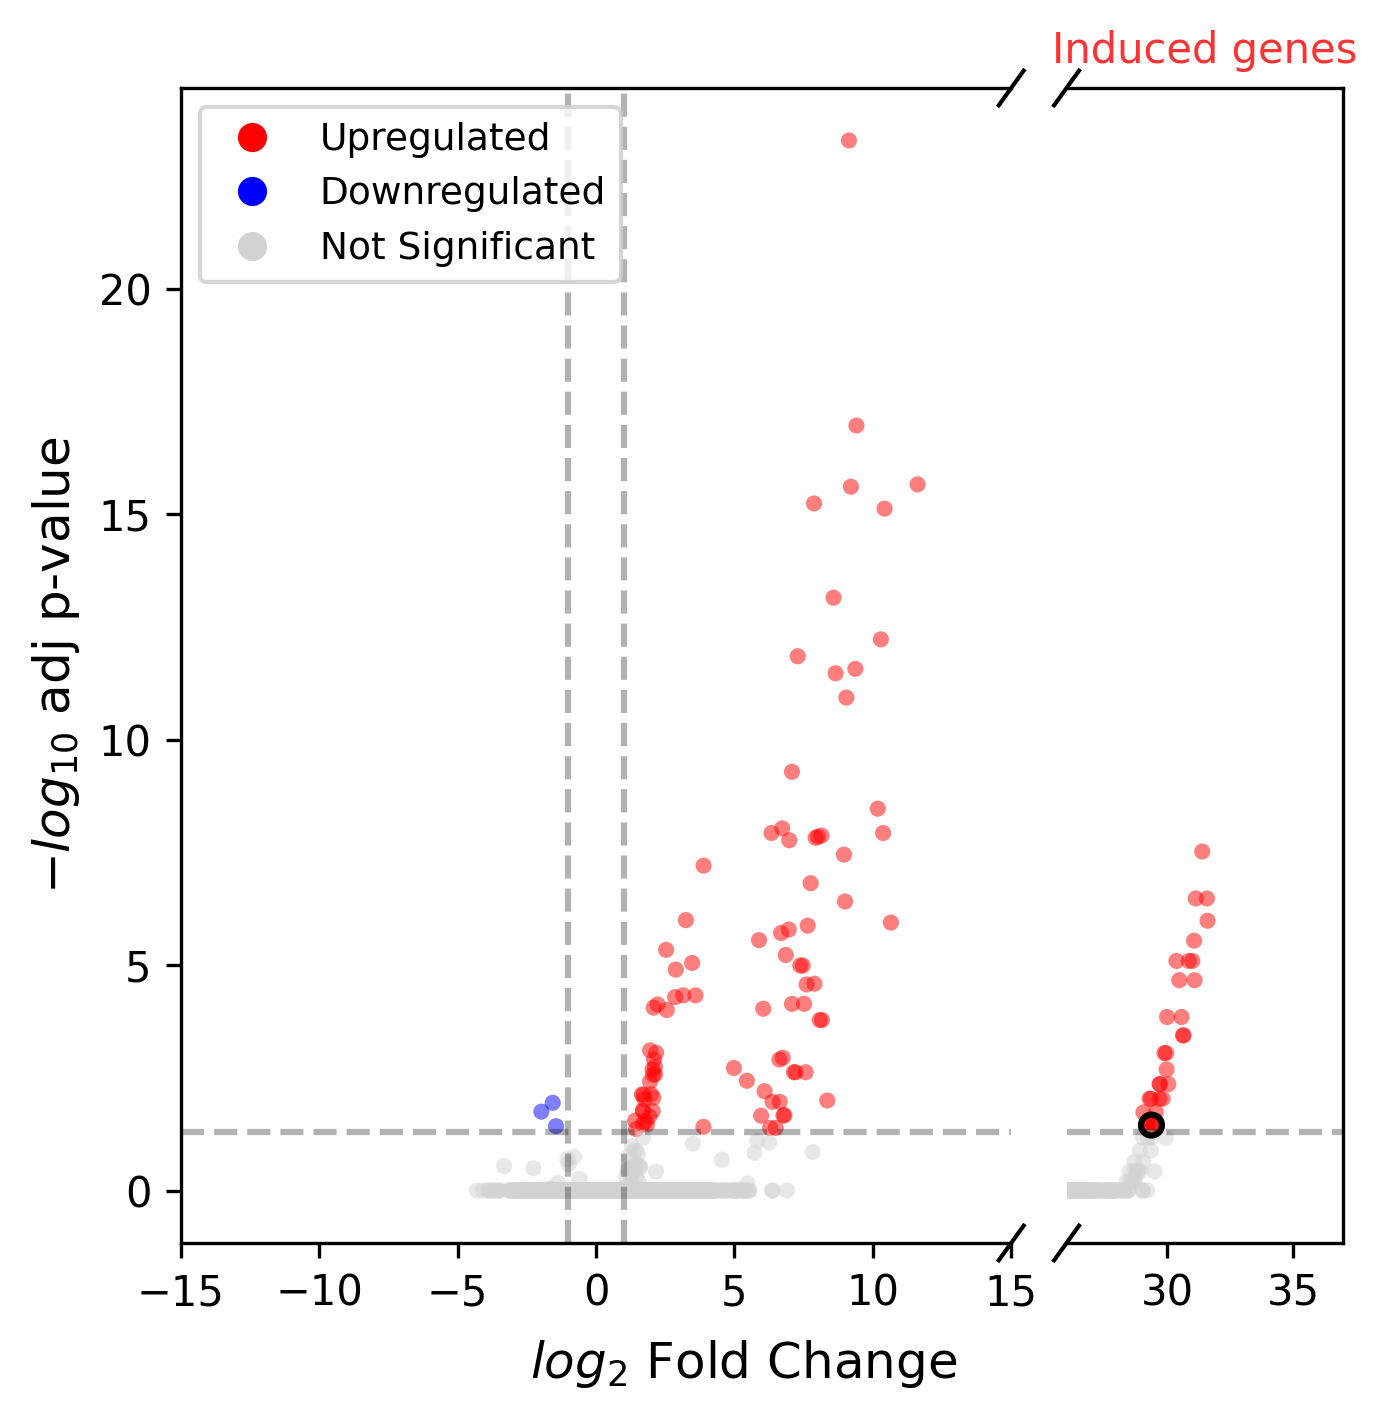

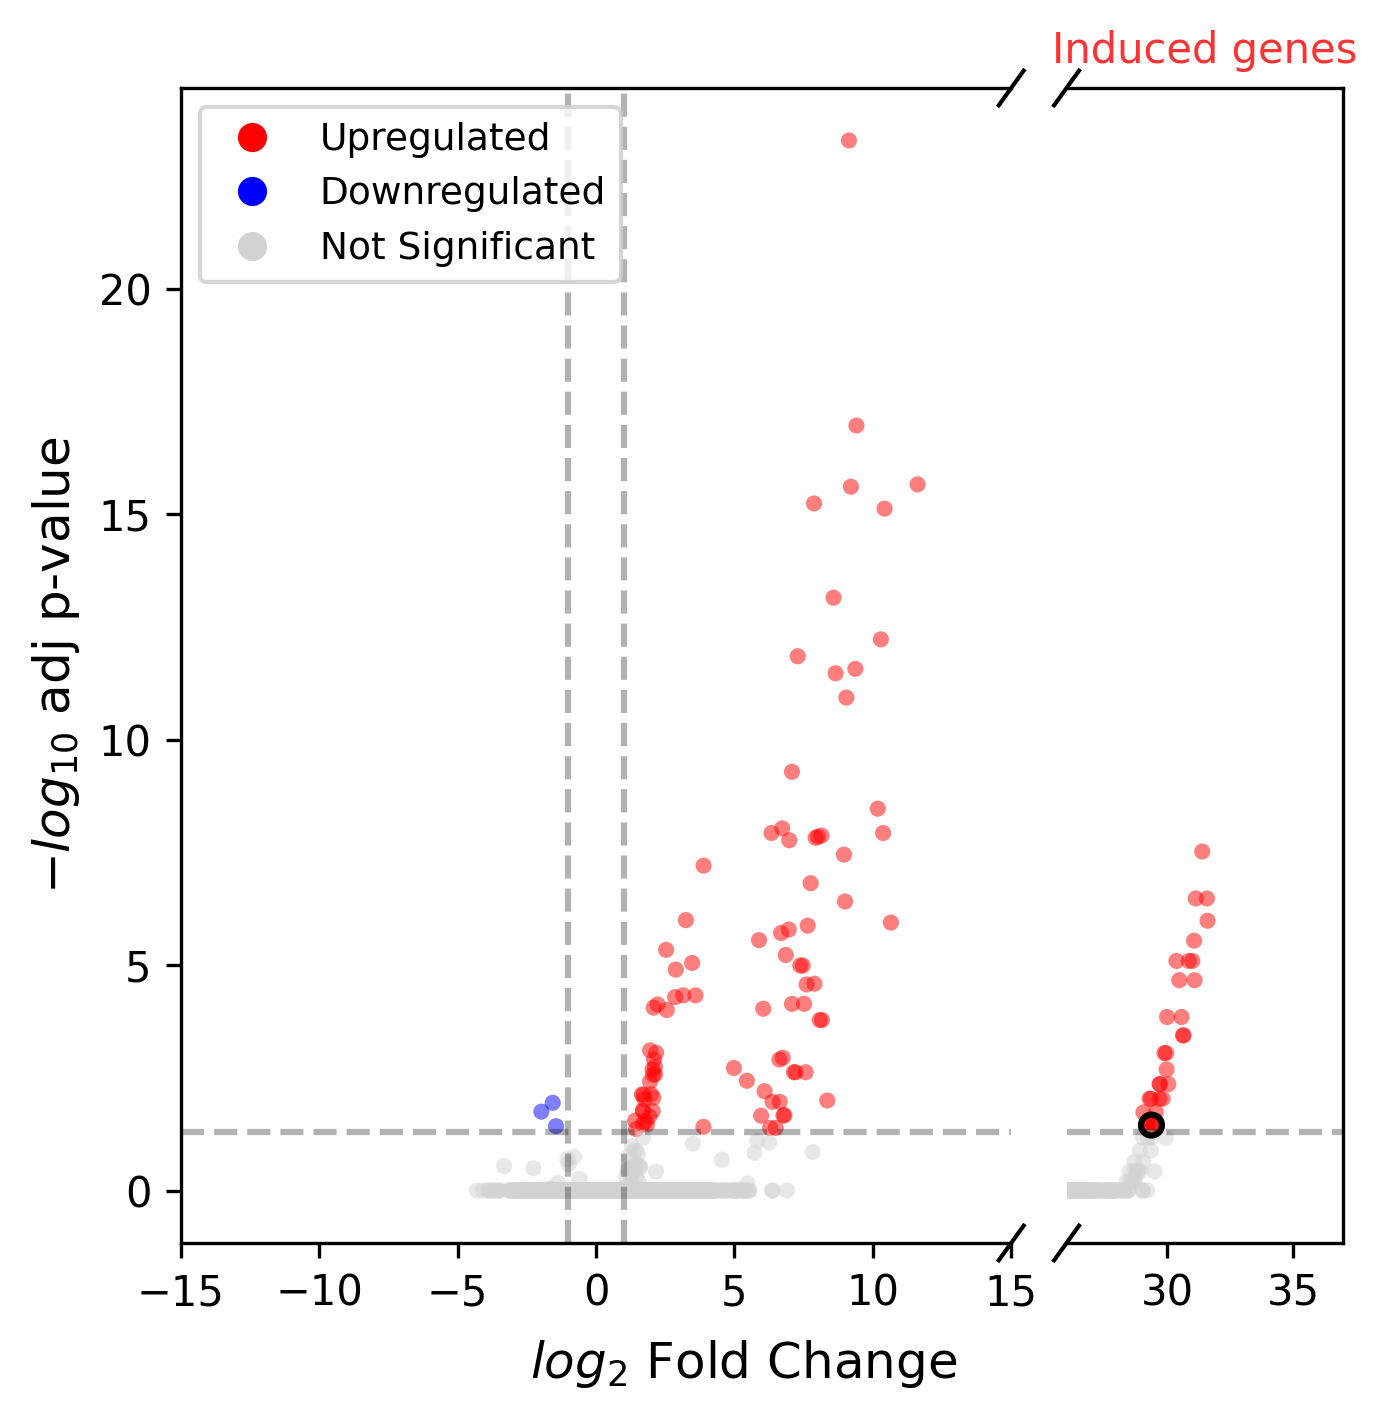

In [9]:
plot_broken_volcano(
    rg,
    genes=highlight_genes,
    highlight_legend_label=highlight_legend_label,
    fc_thr=volcano_fc_thr,
    fdr_thr=volcano_fdr_thr,
    main_lim=volcano_main_lim,
    outlier_start=volcano_outlier_start,
    outlier_end=volcano_outlier_end,
    save_path=volcano_png,
)